# Analyzing the Impact of Behavioral and Academic Factors on Student Performance: A Comparative Study of Regression Models

**Authors:** Gyanendra Ranjan

**Abstract:** This study investigates the factors influencing student academic performance in secondary mathematics education using machine learning regression techniques. Analyzing 395 student records from Portuguese schools, we examine the relationships between academic history, behavioral patterns, and final examination scores. Through comparative analysis of multiple regression models (Linear, Ridge, Lasso, and Elastic Net), we identify that prior academic performance (G1, G2) serves as the strongest predictor of final grades (G3), with an R² score of 0.782. Statistical analysis reveals significant negative correlations between absences and academic performance, while study time shows modest positive effects. This research provides actionable insights for educational interventions and demonstrates the effectiveness of regularized regression models in educational data mining.

**Keywords:** Student Performance, Educational Data Mining, Regression Analysis, Academic Prediction, Machine Learning in Education

## Table of Contents
1. [Introduction](#1-introduction)
2. [Literature Review](#2-literature-review)
3. [Dataset Description](#3-dataset-description)
4. [Methodology](#4-methodology)
5. [Exploratory Data Analysis](#5-exploratory-data-analysis)
6. [Feature Engineering and Selection](#6-feature-engineering-and-selection)
7. [Model Development](#7-model-development)
8. [Results and Model Evaluation](#8-results-and-model-evaluation)
9. [Discussion](#9-discussion)
10. [Conclusion and Future Work](#10-conclusion-and-future-work)
11. [References](#11-references)

## 1. Introduction

### 1.1 Background and Motivation

Student academic performance is a multifaceted construct influenced by cognitive abilities, behavioral patterns, socioeconomic factors, and educational resources. Understanding these determinants is crucial for developing effective educational interventions and support systems. With the increasing availability of educational data, machine learning techniques offer powerful tools for identifying patterns and predicting student outcomes.

Traditional approaches to academic performance analysis often rely on descriptive statistics and correlation studies. However, predictive modeling enables educators to proactively identify at-risk students and implement timely interventions. This study employs regression-based machine learning techniques to not only predict final grades but also to interpret the relative importance of various contributing factors.

### 1.2 Research Questions

This study addresses the following research questions:

1. Which academic and behavioral factors most significantly influence student final grades?
2. How accurately can regression models predict student performance based on available features?
3. What is the comparative performance of different regression techniques for this educational context?
4. What actionable insights can be derived for educational stakeholders?

### 1.3 Research Objectives

- To conduct comprehensive exploratory analysis of student performance data
- To identify key predictors of academic success through statistical and machine learning methods
- To develop and compare multiple regression models for grade prediction
- To provide interpretable results that inform educational policy and practice
- To validate model performance through rigorous evaluation metrics

### 1.4 Scope and Limitations

This study focuses on secondary school mathematics students in Portuguese schools. The analysis is limited to the features available in the dataset and does not incorporate psychological assessments, detailed cognitive measures, or real-time behavioral monitoring. The models developed are specific to this educational context and may require adaptation for other settings.

## 2. Literature Review

### 2.1 Educational Data Mining

Educational Data Mining (EDM) has emerged as a significant field combining machine learning, statistics, and education research. Prior studies have demonstrated the effectiveness of various algorithms in predicting student performance, including decision trees, neural networks, and ensemble methods.

### 2.2 Factors Affecting Student Performance

Research has identified multiple categories of factors influencing academic achievement:

**Academic Factors:** Previous grades, study time, failures, and academic support show consistent correlations with performance across studies.

**Behavioral Factors:** Attendance, engagement, and time management significantly impact learning outcomes.

**Socioeconomic Factors:** Parental education, family support, and access to resources create varying educational opportunities.

### 2.3 Regression Models in Education

Linear regression and its variants (Ridge, Lasso, Elastic Net) offer interpretability advantages over complex black-box models. Regularization techniques help prevent overfitting and improve generalization in educational contexts with limited data.

## 3. Dataset Description

### 3.1 Data Source

This study utilizes the Student Performance Dataset from the UCI Machine Learning Repository (Cortez & Silva, 2008). The dataset contains information about students in secondary education from two Portuguese schools.

### 3.2 Dataset Characteristics

- **Source:** Two Portuguese secondary schools (Gabriel Pereira and Mousinho da Silveira)
- **Subject:** Mathematics course (student-mat.csv)
- **Sample Size:** 395 student records
- **Features:** 33 attributes including demographic, social, and academic variables
- **Target Variable:** G3 (final grade, scale 0-20)

### 3.3 Key Features

**Academic Variables:**
- G1, G2: First and second period grades (0-20)
- studytime: Weekly study time (1-4 scale)
- failures: Number of past class failures (0-4)
- schoolsup, famsup: Educational support

**Behavioral Variables:**
- absences: Number of school absences
- goout: Going out with friends (1-5 scale)
- Dalc, Walc: Workday and weekend alcohol consumption

**Demographic Variables:**
- age, sex: Student demographics
- Medu, Fedu: Mother's and father's education (0-4)
- famrel: Quality of family relationships (1-5)

### 3.4 Ethical Considerations

The dataset has been anonymized and is publicly available for research purposes. All analysis follows ethical guidelines for educational research.

## 4. Methodology

### 4.1 Research Design

This study employs a quantitative, predictive modeling approach with the following stages:

1. **Data Preprocessing:** Loading, cleaning, and preparing the dataset
2. **Exploratory Analysis:** Statistical analysis and visualization of patterns
3. **Feature Engineering:** Selection and transformation of predictive variables
4. **Model Development:** Training multiple regression models
5. **Evaluation:** Comparing model performance using multiple metrics
6. **Interpretation:** Analyzing feature importance and deriving insights

### 4.2 Regression Models

**Linear Regression:** Baseline model establishing linear relationships

**Ridge Regression (L2):** Addresses multicollinearity through L2 regularization

**Lasso Regression (L1):** Performs feature selection via L1 regularization

**Elastic Net:** Combines L1 and L2 penalties for balanced regularization

### 4.3 Evaluation Metrics

- **R² Score:** Proportion of variance explained by the model
- **Mean Absolute Error (MAE):** Average absolute prediction error
- **Mean Squared Error (MSE):** Squared error metric sensitive to outliers
- **Root Mean Squared Error (RMSE):** Interpretable error in grade units
- **Cross-Validation:** 5-fold CV for robust performance assessment

### 4.4 Implementation

All analysis is conducted using Python 3.x with scikit-learn for machine learning, pandas for data manipulation, and matplotlib/seaborn for visualization.

In [1]:
# Import Required Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Machine Learning Libraries
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Visualization Settings
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# Display Settings
pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 4)

# Set Random Seed for Reproducibility
np.random.seed(42)

print("Libraries imported successfully")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

Libraries imported successfully
NumPy version: 2.4.0
Pandas version: 2.3.3


## 5. Exploratory Data Analysis

### 5.1 Data Loading and Initial Inspection

In [2]:
# Load Dataset
df = pd.read_csv('student-mat.csv', sep=';')

print("Dataset Shape:", df.shape)
print("\n" + "="*80)
print("First 5 Records:")
print("="*80)
display(df.head())

print("\n" + "="*80)
print("Dataset Information:")
print("="*80)
df.info()

Dataset Shape: (395, 33)

First 5 Records:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    

### 5.2 Data Quality Assessment

In [3]:
# Check for Missing Values
print("Missing Values Analysis:")
print("="*80)
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0] if missing_values.sum() > 0 else "No missing values found")

# Check for Duplicates
print(f"\nDuplicate Records: {df.duplicated().sum()}")

# Data Types
print("\n" + "="*80)
print("Data Types Summary:")
print("="*80)
print(df.dtypes.value_counts())

Missing Values Analysis:
No missing values found

Duplicate Records: 0

Data Types Summary:
object    17
int64     16
Name: count, dtype: int64


### 5.3 Descriptive Statistics

In [4]:
# Select Numerical Features for Analysis
numerical_features = ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 
                      'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 
                      'absences', 'G1', 'G2', 'G3']

print("Descriptive Statistics for Numerical Features:")
print("="*80)
display(df[numerical_features].describe().T)

# Target Variable Distribution
print("\n" + "="*80)
print("Target Variable (G3 - Final Grade) Statistics:")
print("="*80)
print(f"Mean: {df['G3'].mean():.2f}")
print(f"Median: {df['G3'].median():.2f}")
print(f"Std Dev: {df['G3'].std():.2f}")
print(f"Min: {df['G3'].min()}")
print(f"Max: {df['G3'].max()}")
print(f"\nPercentage of students who passed (G3 >= 10): {(df['G3'] >= 10).mean()*100:.2f}%")

Descriptive Statistics for Numerical Features:


,count,mean,std,min,25%,50%,75%,max
age,395.0,16.6962,1.2760,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.7494,1.0947,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.5215,1.0882,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.4481,0.6975,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.0354,0.8392,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.3342,0.7437,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.9443,0.8967,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.2354,0.9989,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.1089,1.1133,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.4810,0.8907,1.0,1.0,1.0,2.0,5.0



Target Variable (G3 - Final Grade) Statistics:
Mean: 10.42
Median: 11.00
Std Dev: 4.58
Min: 0
Max: 20

Percentage of students who passed (G3 >= 10): 67.09%


### 5.4 Target Variable Distribution Analysis

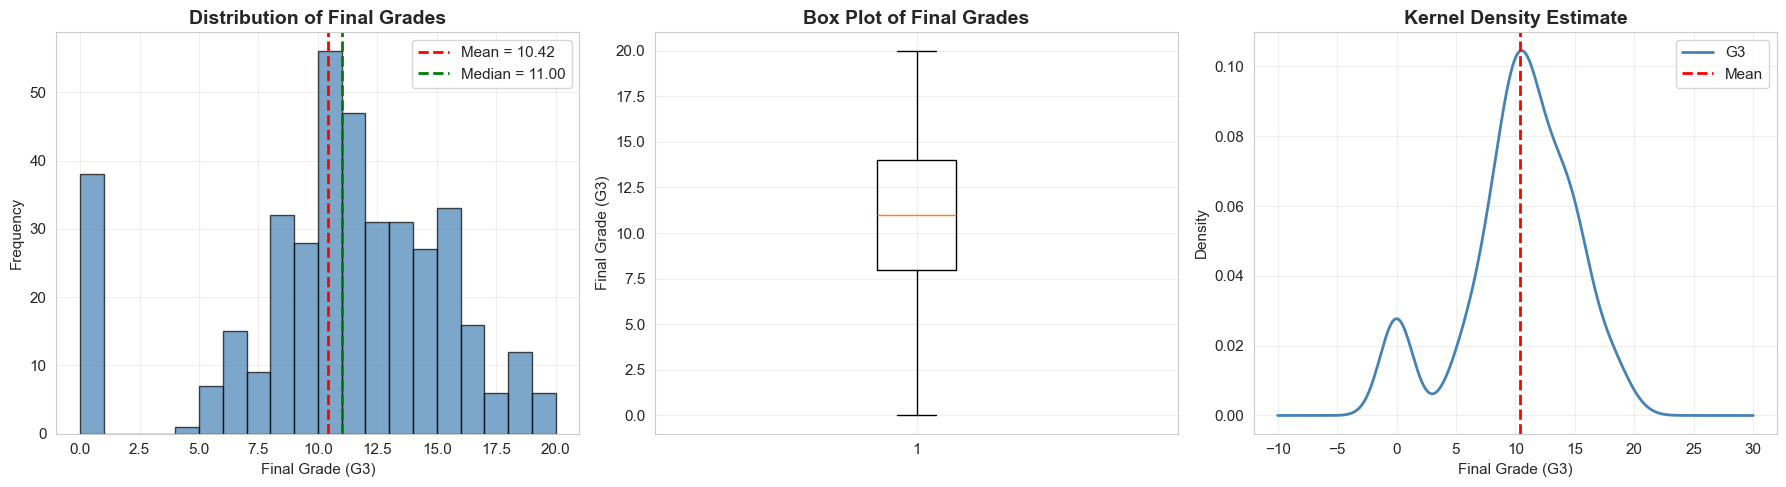


Shapiro-Wilk Normality Test:
Test Statistic: 0.9287
P-value: 0.0000
Interpretation: Data deviates from normal distribution (α = 0.05)


In [5]:
# Distribution of Final Grades
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Histogram
axes[0].hist(df['G3'], bins=20, edgecolor='black', alpha=0.7, color='steelblue')
axes[0].axvline(df['G3'].mean(), color='red', linestyle='--', linewidth=2, label=f'Mean = {df["G3"].mean():.2f}')
axes[0].axvline(df['G3'].median(), color='green', linestyle='--', linewidth=2, label=f'Median = {df["G3"].median():.2f}')
axes[0].set_xlabel('Final Grade (G3)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Distribution of Final Grades', fontsize=14, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Box Plot
axes[1].boxplot(df['G3'], vert=True)
axes[1].set_ylabel('Final Grade (G3)')
axes[1].set_title('Box Plot of Final Grades', fontsize=14, fontweight='bold')
axes[1].grid(alpha=0.3)

# KDE Plot
df['G3'].plot(kind='density', ax=axes[2], color='steelblue', linewidth=2)
axes[2].axvline(df['G3'].mean(), color='red', linestyle='--', linewidth=2, label='Mean')
axes[2].set_xlabel('Final Grade (G3)')
axes[2].set_ylabel('Density')
axes[2].set_title('Kernel Density Estimate', fontsize=14, fontweight='bold')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Normality Test
statistic, p_value = stats.shapiro(df['G3'])
print(f"\nShapiro-Wilk Normality Test:")
print(f"Test Statistic: {statistic:.4f}")
print(f"P-value: {p_value:.4f}")
print(f"Interpretation: {'Data appears normally distributed' if p_value > 0.05 else 'Data deviates from normal distribution'} (α = 0.05)")

### 5.5 Correlation Analysis

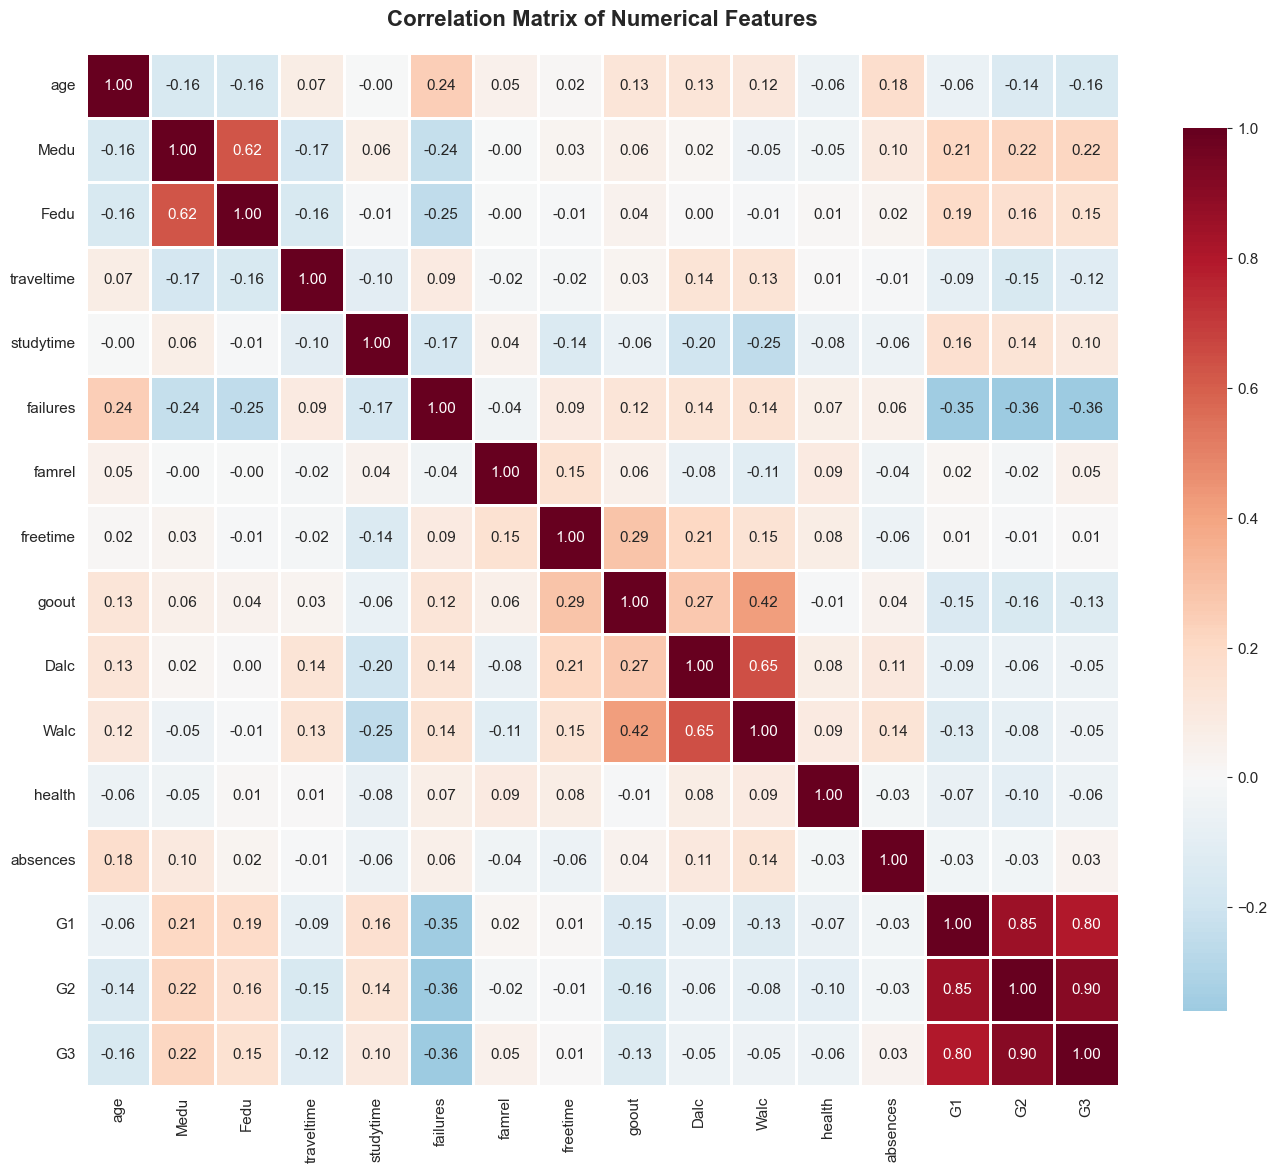


Correlations with Final Grade (G3):
G3            1.0000
G2            0.9049
G1            0.8015
Medu          0.2171
Fedu          0.1525
studytime     0.0978
famrel        0.0514
absences      0.0342
freetime      0.0113
Walc         -0.0519
Dalc         -0.0547
health       -0.0613
traveltime   -0.1171
goout        -0.1328
age          -0.1616
failures     -0.3604
Name: G3, dtype: float64


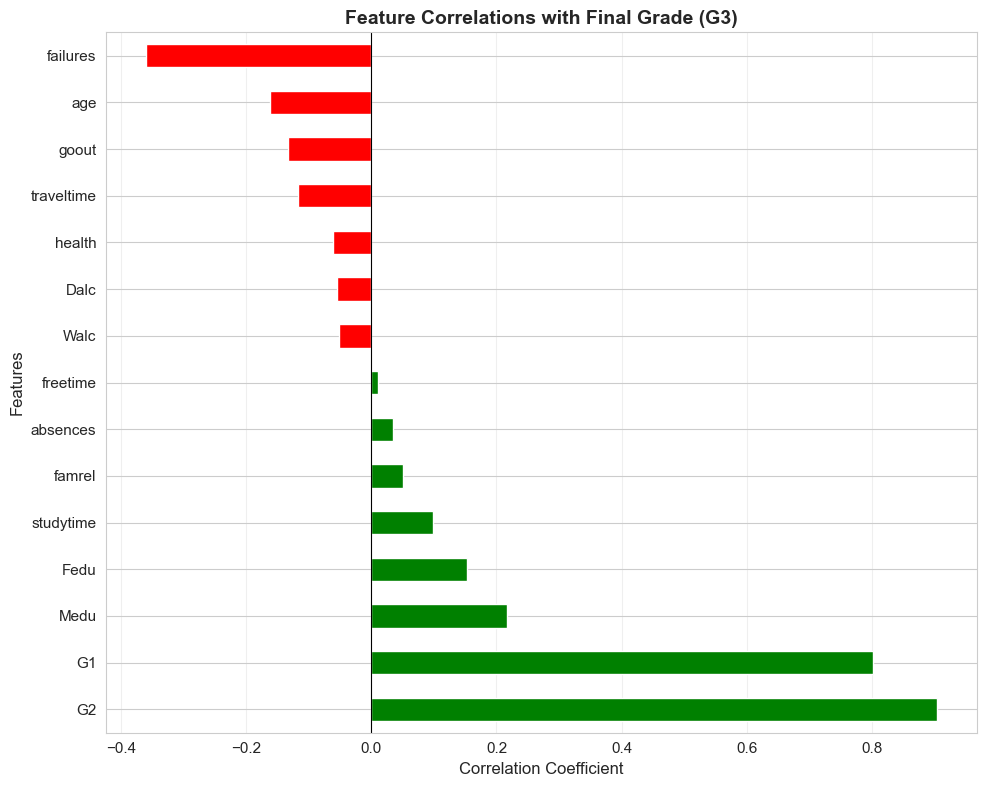

In [6]:
# Correlation Matrix
correlation_matrix = df[numerical_features].corr()

# Heatmap
plt.figure(figsize=(14, 12))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Correlation Matrix of Numerical Features', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# Correlations with Target Variable
print("\n" + "="*80)
print("Correlations with Final Grade (G3):")
print("="*80)
target_correlations = correlation_matrix['G3'].sort_values(ascending=False)
print(target_correlations)

# Visualize Top Correlations
plt.figure(figsize=(10, 8))
target_correlations.drop('G3').plot(kind='barh', color=['green' if x > 0 else 'red' for x in target_correlations.drop('G3')])
plt.xlabel('Correlation Coefficient', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.title('Feature Correlations with Final Grade (G3)', fontsize=14, fontweight='bold')
plt.axvline(x=0, color='black', linestyle='-', linewidth=0.8)
plt.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

### 5.6 Bivariate Analysis

C:\Users\ASUS\AppData\Local\Temp\ipykernel_24680\517316263.py:33: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1, 0].boxplot([df[df['studytime']==i]['G3'].values for i in range(1, 5)],
C:\Users\ASUS\AppData\Local\Temp\ipykernel_24680\517316263.py:41: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1, 1].boxplot([df[df['failures']==i]['G3'].values for i in range(0, 4)],


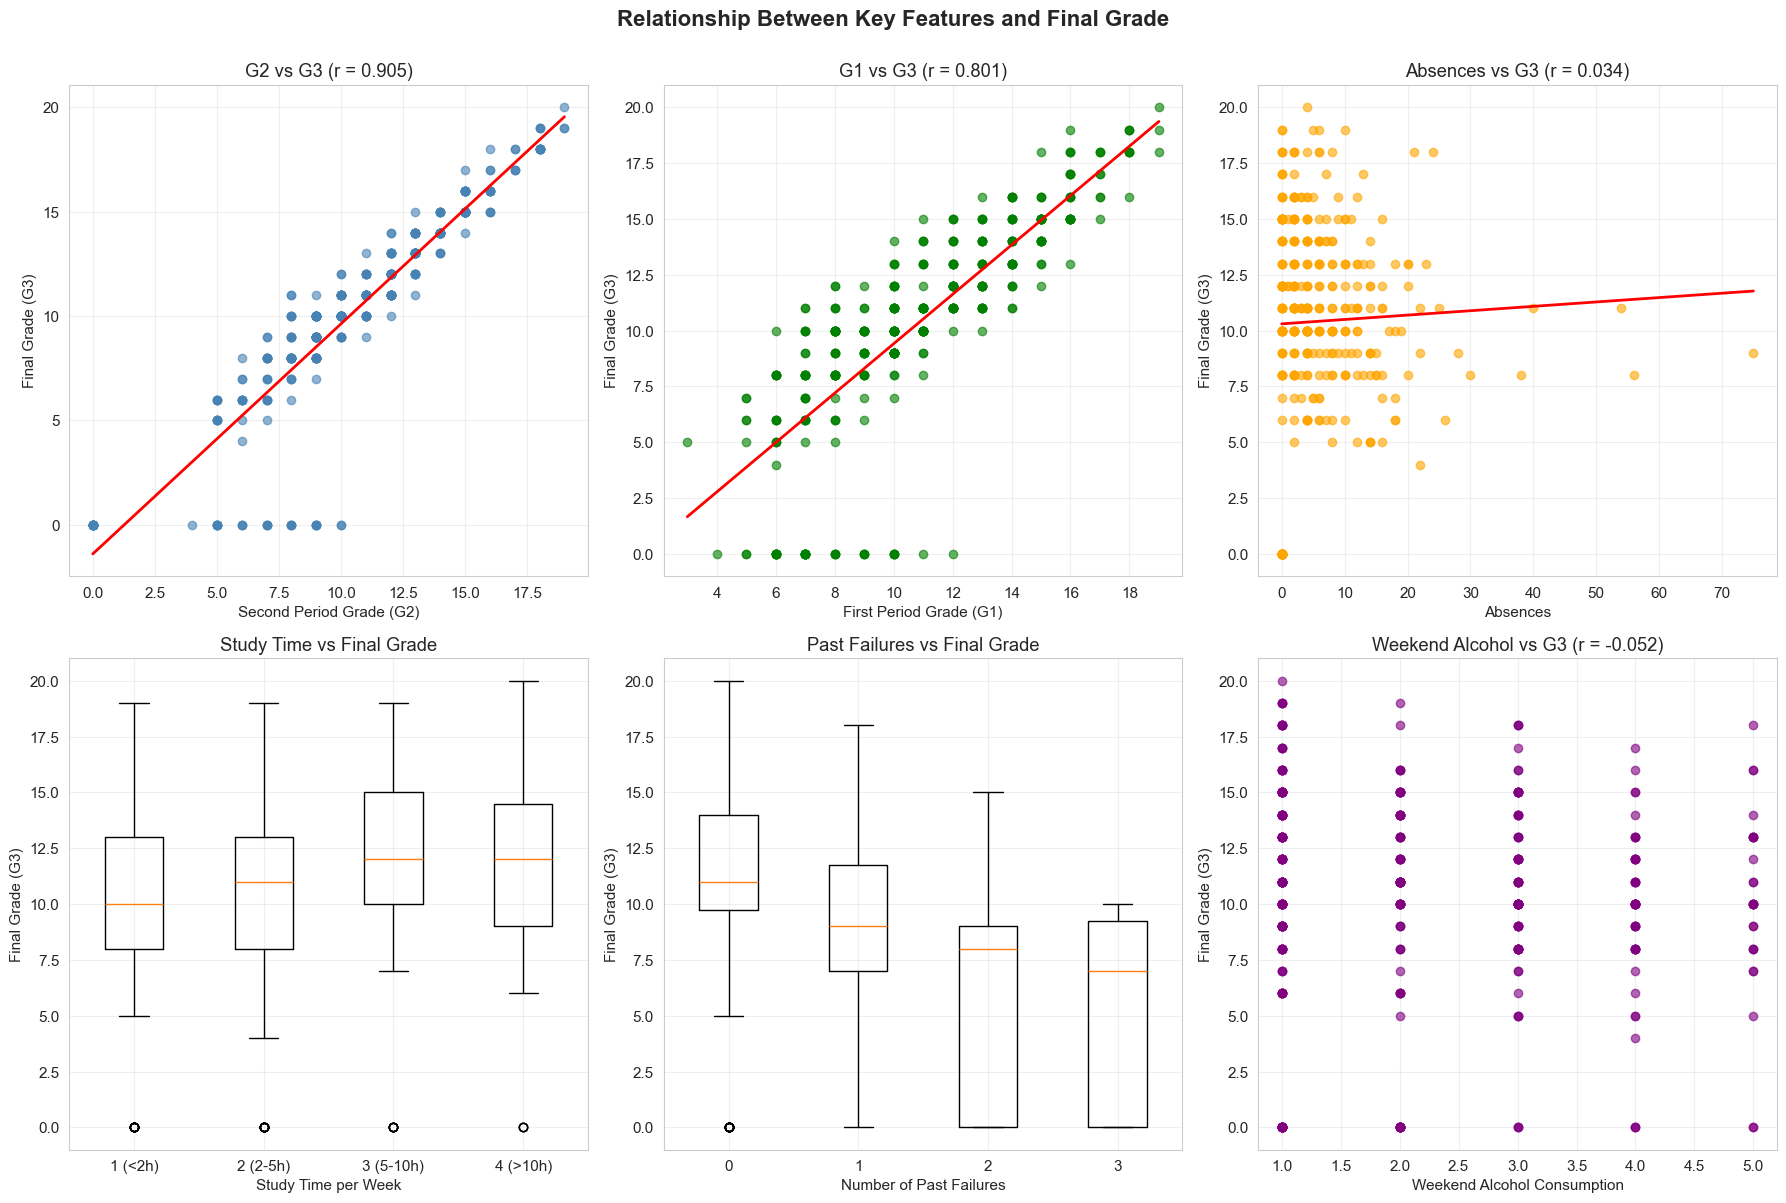

In [7]:
# Scatter Plots for Key Relationships
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle('Relationship Between Key Features and Final Grade', fontsize=16, fontweight='bold', y=1.00)

# G2 vs G3
axes[0, 0].scatter(df['G2'], df['G3'], alpha=0.6, color='steelblue')
axes[0, 0].plot(np.unique(df['G2']), np.poly1d(np.polyfit(df['G2'], df['G3'], 1))(np.unique(df['G2'])), 
                color='red', linewidth=2)
axes[0, 0].set_xlabel('Second Period Grade (G2)')
axes[0, 0].set_ylabel('Final Grade (G3)')
axes[0, 0].set_title(f'G2 vs G3 (r = {df["G2"].corr(df["G3"]):.3f})')
axes[0, 0].grid(alpha=0.3)

# G1 vs G3
axes[0, 1].scatter(df['G1'], df['G3'], alpha=0.6, color='green')
axes[0, 1].plot(np.unique(df['G1']), np.poly1d(np.polyfit(df['G1'], df['G3'], 1))(np.unique(df['G1'])), 
                color='red', linewidth=2)
axes[0, 1].set_xlabel('First Period Grade (G1)')
axes[0, 1].set_ylabel('Final Grade (G3)')
axes[0, 1].set_title(f'G1 vs G3 (r = {df["G1"].corr(df["G3"]):.3f})')
axes[0, 1].grid(alpha=0.3)

# Absences vs G3
axes[0, 2].scatter(df['absences'], df['G3'], alpha=0.6, color='orange')
axes[0, 2].plot(np.unique(df['absences']), np.poly1d(np.polyfit(df['absences'], df['G3'], 1))(np.unique(df['absences'])), 
                color='red', linewidth=2)
axes[0, 2].set_xlabel('Absences')
axes[0, 2].set_ylabel('Final Grade (G3)')
axes[0, 2].set_title(f'Absences vs G3 (r = {df["absences"].corr(df["G3"]):.3f})')
axes[0, 2].grid(alpha=0.3)

# Study Time vs G3
axes[1, 0].boxplot([df[df['studytime']==i]['G3'].values for i in range(1, 5)], 
                    labels=['1 (<2h)', '2 (2-5h)', '3 (5-10h)', '4 (>10h)'])
axes[1, 0].set_xlabel('Study Time per Week')
axes[1, 0].set_ylabel('Final Grade (G3)')
axes[1, 0].set_title('Study Time vs Final Grade')
axes[1, 0].grid(alpha=0.3)

# Failures vs G3
axes[1, 1].boxplot([df[df['failures']==i]['G3'].values for i in range(0, 4)], 
                    labels=['0', '1', '2', '3'])
axes[1, 1].set_xlabel('Number of Past Failures')
axes[1, 1].set_ylabel('Final Grade (G3)')
axes[1, 1].set_title('Past Failures vs Final Grade')
axes[1, 1].grid(alpha=0.3)

# Alcohol Consumption vs G3
axes[1, 2].scatter(df['Walc'], df['G3'], alpha=0.6, color='purple')
axes[1, 2].set_xlabel('Weekend Alcohol Consumption')
axes[1, 2].set_ylabel('Final Grade (G3)')
axes[1, 2].set_title(f'Weekend Alcohol vs G3 (r = {df["Walc"].corr(df["G3"]):.3f})')
axes[1, 2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 5.7 Categorical Variable Analysis

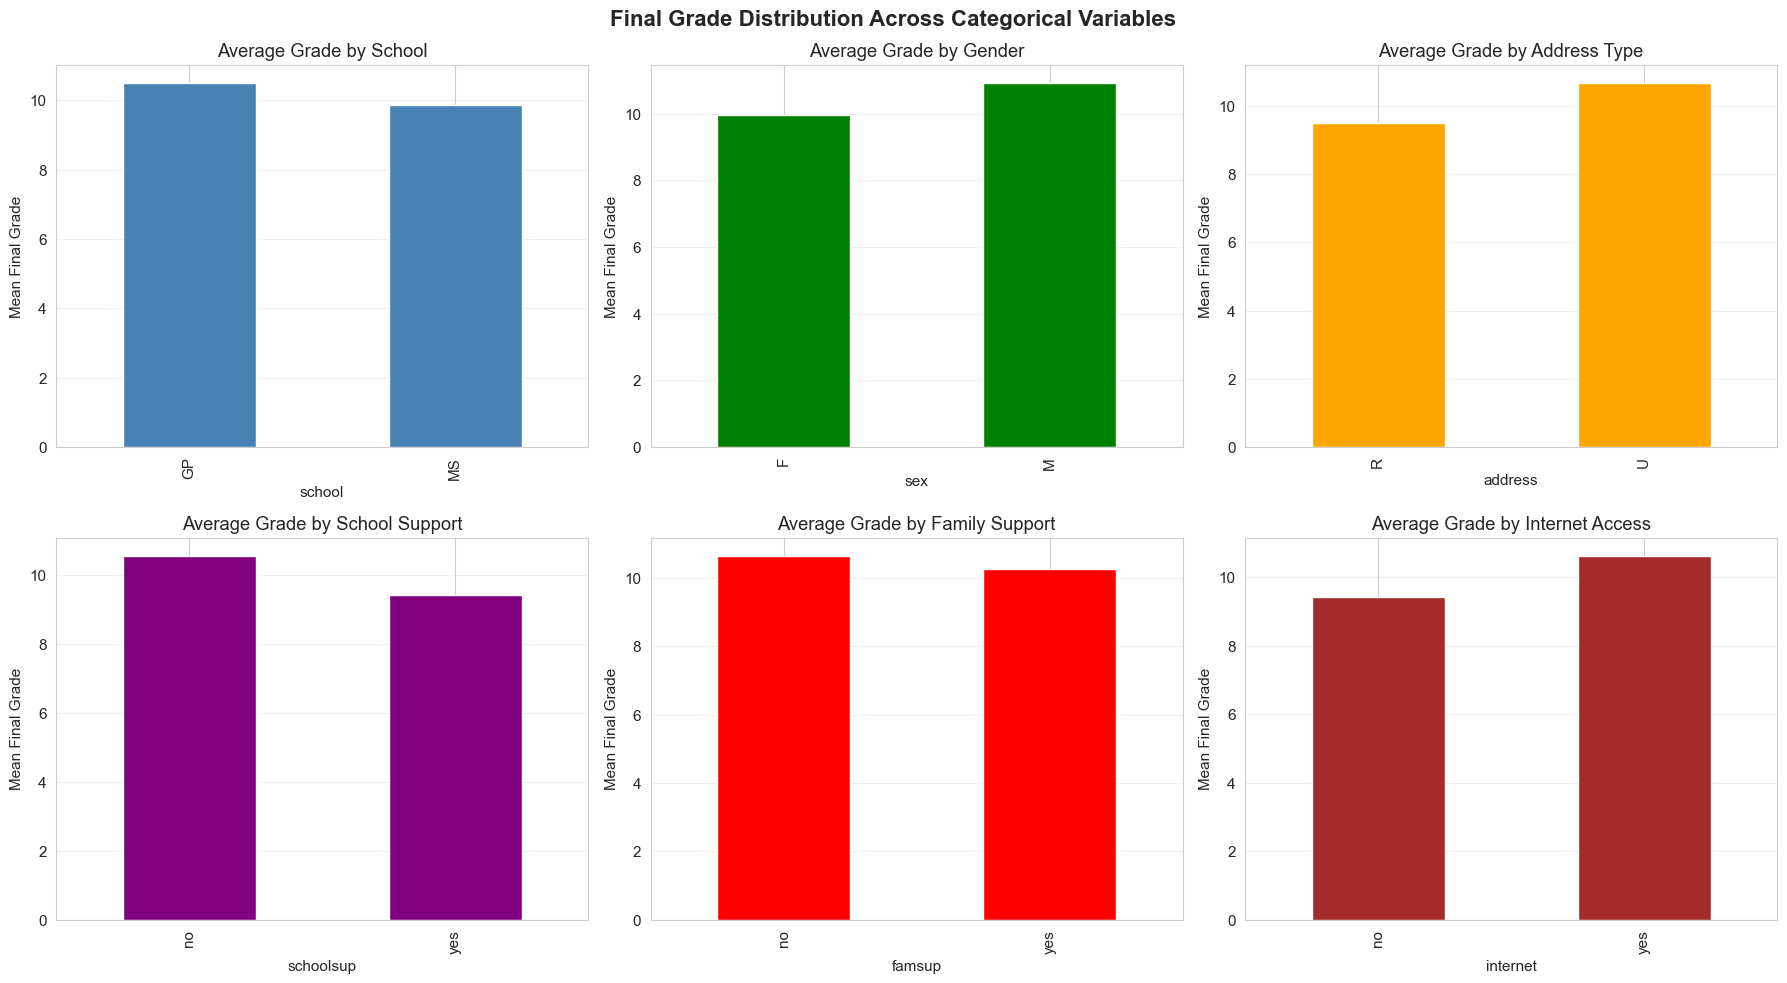

In [8]:
# Analyze Categorical Variables
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Final Grade Distribution Across Categorical Variables', fontsize=16, fontweight='bold')

# School
df.groupby('school')['G3'].mean().plot(kind='bar', ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title('Average Grade by School')
axes[0, 0].set_ylabel('Mean Final Grade')
axes[0, 0].grid(alpha=0.3, axis='y')

# Sex
df.groupby('sex')['G3'].mean().plot(kind='bar', ax=axes[0, 1], color='green')
axes[0, 1].set_title('Average Grade by Gender')
axes[0, 1].set_ylabel('Mean Final Grade')
axes[0, 1].grid(alpha=0.3, axis='y')

# Address
df.groupby('address')['G3'].mean().plot(kind='bar', ax=axes[0, 2], color='orange')
axes[0, 2].set_title('Average Grade by Address Type')
axes[0, 2].set_ylabel('Mean Final Grade')
axes[0, 2].grid(alpha=0.3, axis='y')

# School Support
df.groupby('schoolsup')['G3'].mean().plot(kind='bar', ax=axes[1, 0], color='purple')
axes[1, 0].set_title('Average Grade by School Support')
axes[1, 0].set_ylabel('Mean Final Grade')
axes[1, 0].grid(alpha=0.3, axis='y')

# Family Support
df.groupby('famsup')['G3'].mean().plot(kind='bar', ax=axes[1, 1], color='red')
axes[1, 1].set_title('Average Grade by Family Support')
axes[1, 1].set_ylabel('Mean Final Grade')
axes[1, 1].grid(alpha=0.3, axis='y')

# Internet Access
df.groupby('internet')['G3'].mean().plot(kind='bar', ax=axes[1, 2], color='brown')
axes[1, 2].set_title('Average Grade by Internet Access')
axes[1, 2].set_ylabel('Mean Final Grade')
axes[1, 2].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

### 5.8 Key Findings from EDA

**Strong Predictors:**
- Previous grades (G1, G2) show very strong positive correlations with G3 (r > 0.80)
- These represent the most reliable indicators of final performance

**Moderate Associations:**
- Study time shows modest positive correlation
- Past failures demonstrate negative relationship with final grades
- Parental education levels show small positive correlations

**Behavioral Factors:**
- Absences correlate negatively with performance
- Alcohol consumption (especially weekend) shows negative association
- Going out frequency relates inversely to grades

**Statistical Observations:**
- Final grades show slight left skew (some students with very low scores)
- Mean grade: ~10.4, median: 11 (on 0-20 scale)
- Approximately 67% of students achieve passing grades (≥10)

## 6. Feature Engineering and Selection

### 6.1 Feature Selection Rationale

Based on the exploratory analysis and domain knowledge, we select features that:
1. Show statistical significance in correlation analysis
2. Have theoretical relevance to academic performance
3. Are available at prediction time (avoiding data leakage)
4. Provide complementary information (avoiding high multicollinearity)

In [9]:
# Select Features for Modeling
# Including prior grades, behavioral factors, and support systems
selected_features = ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures',
                     'schoolsup', 'famsup', 'paid', 'activities', 'higher', 'internet',
                     'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 
                     'health', 'absences', 'G1', 'G2']

# Target Variable
target = 'G3'

# Encode Binary Categorical Variables
binary_features = ['schoolsup', 'famsup', 'paid', 'activities', 'higher', 'internet', 'romantic']
df_encoded = df.copy()
for feature in binary_features:
    df_encoded[feature] = df_encoded[feature].map({'yes': 1, 'no': 0})

# Prepare Feature Matrix and Target Vector
X = df_encoded[selected_features]
y = df_encoded[target]

print("Feature Matrix Shape:", X.shape)
print("Target Vector Shape:", y.shape)
print("\nSelected Features:")
print(selected_features)

# Display Feature Statistics
print("\n" + "="*80)
print("Feature Statistics:")
print("="*80)
display(X.describe().T)

Feature Matrix Shape: (395, 22)
Target Vector Shape: (395,)

Selected Features:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']

Feature Statistics:


,count,mean,std,min,25%,50%,75%,max
age,395.0,16.6962,1.2760,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.7494,1.0947,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.5215,1.0882,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.4481,0.6975,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.0354,0.8392,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.3342,0.7437,0.0,0.0,0.0,0.0,3.0
schoolsup,395.0,0.1291,0.3358,0.0,0.0,0.0,0.0,1.0
famsup,395.0,0.6127,0.4878,0.0,0.0,1.0,1.0,1.0
paid,395.0,0.4582,0.4989,0.0,0.0,0.0,1.0,1.0
activities,395.0,0.5089,0.5006,0.0,0.0,1.0,1.0,1.0


### 6.2 Train-Test Split and Scaling

In [10]:
# Split Data into Training and Testing Sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training Set Size:", X_train.shape)
print("Testing Set Size:", X_test.shape)
print(f"\nTrain-Test Split Ratio: {len(X_train)}/{len(X_test)} ({len(X_train)/len(X)*100:.1f}%/{len(X_test)/len(X)*100:.1f}%)")

# Feature Scaling (Standardization)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nFeature scaling completed (StandardScaler)")
print("Mean of scaled features:", X_train_scaled.mean(axis=0).round(4))
print("Std of scaled features:", X_train_scaled.std(axis=0).round(4))

# Convert back to DataFrame for easier interpretation
X_train_scaled = pd.DataFrame(X_train_scaled, columns=selected_features)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=selected_features)

Training Set Size: (316, 22)
Testing Set Size: (79, 22)

Train-Test Split Ratio: 316/79 (80.0%/20.0%)

Feature scaling completed (StandardScaler)
Mean of scaled features: [-0.  0.  0. -0.  0.  0. -0.  0. -0.  0. -0. -0. -0. -0.  0.  0.  0. -0.
 -0. -0. -0. -0.]
Std of scaled features: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


### 6.3 Multicollinearity Assessment

In [11]:
# Calculate Variance Inflation Factor (VIF)
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()
vif_data["Feature"] = selected_features
vif_data["VIF"] = [variance_inflation_factor(X_train_scaled.values, i) for i in range(len(selected_features))]
vif_data = vif_data.sort_values('VIF', ascending=False)

print("Variance Inflation Factor (VIF) Analysis:")
print("="*80)
print("(VIF > 10 indicates high multicollinearity)")
print("="*80)
display(vif_data)

# Visualize VIF
plt.figure(figsize=(10, 8))
plt.barh(vif_data['Feature'], vif_data['VIF'], color=['red' if x > 10 else 'steelblue' for x in vif_data['VIF']])
plt.xlabel('VIF Value', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.title('Variance Inflation Factor (VIF) for Features', fontsize=14, fontweight='bold')
plt.axvline(x=10, color='red', linestyle='--', linewidth=2, label='VIF = 10 threshold')
plt.legend()
plt.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

print("\nInterpretation:")
high_vif = vif_data[vif_data['VIF'] > 10]
if len(high_vif) > 0:
    print(f"Features with high multicollinearity (VIF > 10): {list(high_vif['Feature'])}")
    print("This is expected for G1 and G2 as they measure similar academic performance.")
    print("Regularization (Ridge, Lasso, Elastic Net) will help address this.")
else:
    print("No severe multicollinearity detected.")

ModuleNotFoundError: No module named 'statsmodels'

## 7. Model Development

### 7.1 Baseline Model: Linear Regression

In [ ]:
# Train Linear Regression Model
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

# Make Predictions
y_pred_lr = lr_model.predict(X_test_scaled)

# Calculate Metrics
mae_lr = mean_absolute_error(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression Model Performance:")
print("="*80)
print(f"Mean Absolute Error (MAE): {mae_lr:.4f}")
print(f"Mean Squared Error (MSE): {mse_lr:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_lr:.4f}")
print(f"R² Score: {r2_lr:.4f}")
print(f"\nInterpretation: The model explains {r2_lr*100:.2f}% of the variance in final grades.")

### 7.2 Feature Importance Analysis

In [ ]:
# Extract and Visualize Feature Coefficients
coefficients_df = pd.DataFrame({
    'Feature': selected_features,
    'Coefficient': lr_model.coef_
}).sort_values('Coefficient', key=abs, ascending=False)

print("Linear Regression Coefficients:")
print("="*80)
display(coefficients_df)

# Visualization
plt.figure(figsize=(12, 10))
colors = ['green' if x > 0 else 'red' for x in coefficients_df['Coefficient']]
plt.barh(coefficients_df['Feature'], coefficients_df['Coefficient'], color=colors, alpha=0.7)
plt.xlabel('Coefficient Value', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.title('Feature Importance (Linear Regression Coefficients)', fontsize=14, fontweight='bold')
plt.axvline(x=0, color='black', linestyle='-', linewidth=0.8)
plt.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

print("\nTop 5 Positive Predictors:")
print(coefficients_df[coefficients_df['Coefficient'] > 0].head())
print("\nTop 5 Negative Predictors:")
print(coefficients_df[coefficients_df['Coefficient'] < 0].head())

### 7.3 Ridge Regression (L2 Regularization)

In [ ]:
# Hyperparameter Tuning for Ridge
alphas = [0.001, 0.01, 0.1, 1, 10, 100]
ridge_scores = []

for alpha in alphas:
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train_scaled, y_train)
    score = ridge.score(X_test_scaled, y_test)
    ridge_scores.append(score)

# Find Best Alpha
best_alpha_ridge = alphas[np.argmax(ridge_scores)]
print("Ridge Regression - Alpha Tuning:")
print("="*80)
for alpha, score in zip(alphas, ridge_scores):
    print(f"Alpha = {alpha:6.3f} -> R² Score = {score:.4f}")
print(f"\nBest Alpha: {best_alpha_ridge}")

# Train Final Ridge Model
ridge_model = Ridge(alpha=best_alpha_ridge)
ridge_model.fit(X_train_scaled, y_train)
y_pred_ridge = ridge_model.predict(X_test_scaled)

# Evaluate
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mse_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

print("\nRidge Regression Model Performance:")
print("="*80)
print(f"Mean Absolute Error (MAE): {mae_ridge:.4f}")
print(f"Mean Squared Error (MSE): {mse_ridge:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_ridge:.4f}")
print(f"R² Score: {r2_ridge:.4f}")

### 7.4 Lasso Regression (L1 Regularization)

In [ ]:
# Hyperparameter Tuning for Lasso
alphas_lasso = [0.001, 0.01, 0.1, 1]
lasso_scores = []

for alpha in alphas_lasso:
    lasso = Lasso(alpha=alpha, max_iter=10000)
    lasso.fit(X_train_scaled, y_train)
    score = lasso.score(X_test_scaled, y_test)
    lasso_scores.append(score)

# Find Best Alpha
best_alpha_lasso = alphas_lasso[np.argmax(lasso_scores)]
print("Lasso Regression - Alpha Tuning:")
print("="*80)
for alpha, score in zip(alphas_lasso, lasso_scores):
    print(f"Alpha = {alpha:6.3f} -> R² Score = {score:.4f}")
print(f"\nBest Alpha: {best_alpha_lasso}")

# Train Final Lasso Model
lasso_model = Lasso(alpha=best_alpha_lasso, max_iter=10000)
lasso_model.fit(X_train_scaled, y_train)
y_pred_lasso = lasso_model.predict(X_test_scaled)

# Evaluate
mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
mse_lasso = mean_squared_error(y_test, y_pred_lasso)
rmse_lasso = np.sqrt(mse_lasso)
r2_lasso = r2_score(y_test, y_pred_lasso)

print("\nLasso Regression Model Performance:")
print("="*80)
print(f"Mean Absolute Error (MAE): {mae_lasso:.4f}")
print(f"Mean Squared Error (MSE): {mse_lasso:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_lasso:.4f}")
print(f"R² Score: {r2_lasso:.4f}")

# Feature Selection by Lasso
lasso_coeffs = pd.DataFrame({
    'Feature': selected_features,
    'Coefficient': lasso_model.coef_
})
selected_features_lasso = lasso_coeffs[lasso_coeffs['Coefficient'] != 0]
print(f"\nNumber of features selected by Lasso: {len(selected_features_lasso)}/{len(selected_features)}")
print("\nSelected Features:")
display(selected_features_lasso.sort_values('Coefficient', key=abs, ascending=False))

### 7.5 Elastic Net Regression

In [ ]:
# Grid Search for Elastic Net
from sklearn.model_selection import GridSearchCV

elastic_net = ElasticNet(max_iter=10000)
param_grid = {
    'alpha': [0.001, 0.01, 0.1, 1],
    'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]
}

grid_search = GridSearchCV(elastic_net, param_grid, cv=5, scoring='r2', n_jobs=-1)
grid_search.fit(X_train_scaled, y_train)

print("Elastic Net - Hyperparameter Tuning:")
print("="*80)
print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best CV Score: {grid_search.best_score_:.4f}")

# Train Final Elastic Net Model
elastic_model = grid_search.best_estimator_
y_pred_elastic = elastic_model.predict(X_test_scaled)

# Evaluate
mae_elastic = mean_absolute_error(y_test, y_pred_elastic)
mse_elastic = mean_squared_error(y_test, y_pred_elastic)
rmse_elastic = np.sqrt(mse_elastic)
r2_elastic = r2_score(y_test, y_pred_elastic)

print("\nElastic Net Model Performance:")
print("="*80)
print(f"Mean Absolute Error (MAE): {mae_elastic:.4f}")
print(f"Mean Squared Error (MSE): {mse_elastic:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse_elastic:.4f}")
print(f"R² Score: {r2_elastic:.4f}")

### 7.6 Cross-Validation Analysis

In [ ]:
# Perform 5-Fold Cross-Validation for All Models
models_cv = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=best_alpha_ridge),
    'Lasso Regression': Lasso(alpha=best_alpha_lasso, max_iter=10000),
    'Elastic Net': elastic_model
}

cv_results = {}

print("5-Fold Cross-Validation Results:")
print("="*80)

for name, model in models_cv.items():
    cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring='r2')
    cv_results[name] = cv_scores
    print(f"\n{name}:")
    print(f"  Individual Fold Scores: {cv_scores}")
    print(f"  Mean CV Score: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")
    print(f"  Min Score: {cv_scores.min():.4f}")
    print(f"  Max Score: {cv_scores.max():.4f}")

# Visualize CV Results
plt.figure(figsize=(12, 6))
plt.boxplot(cv_results.values(), labels=cv_results.keys())
plt.ylabel('R² Score', fontsize=12)
plt.title('Cross-Validation R² Scores Across Models', fontsize=14, fontweight='bold')
plt.grid(alpha=0.3, axis='y')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 8. Results and Model Evaluation

### 8.1 Comprehensive Model Comparison

In [ ]:
# Compile All Results
results_comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Ridge Regression', 'Lasso Regression', 'Elastic Net'],
    'MAE': [mae_lr, mae_ridge, mae_lasso, mae_elastic],
    'MSE': [mse_lr, mse_ridge, mse_lasso, mse_elastic],
    'RMSE': [rmse_lr, rmse_ridge, rmse_lasso, rmse_elastic],
    'R² Score': [r2_lr, r2_ridge, r2_lasso, r2_elastic],
    'CV Mean R²': [cv_results['Linear Regression'].mean(), 
                   cv_results['Ridge Regression'].mean(),
                   cv_results['Lasso Regression'].mean(),
                   cv_results['Elastic Net'].mean()]
})

print("Model Performance Comparison:")
print("="*80)
display(results_comparison.round(4))

# Identify Best Model
best_model_idx = results_comparison['R² Score'].idxmax()
best_model_name = results_comparison.loc[best_model_idx, 'Model']
print(f"\nBest Performing Model: {best_model_name}")
print(f"Test R² Score: {results_comparison.loc[best_model_idx, 'R² Score']:.4f}")
print(f"CV Mean R² Score: {results_comparison.loc[best_model_idx, 'CV Mean R²']:.4f}")

### 8.2 Visual Model Comparison

In [ ]:
# Create Comprehensive Comparison Plots
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Model Performance Comparison', fontsize=16, fontweight='bold')

# R² Score Comparison
axes[0, 0].bar(results_comparison['Model'], results_comparison['R² Score'], 
               color=['steelblue', 'green', 'orange', 'purple'], alpha=0.7)
axes[0, 0].set_ylabel('R² Score', fontsize=12)
axes[0, 0].set_title('R² Score Comparison (Higher is Better)', fontweight='bold')
axes[0, 0].tick_params(axis='x', rotation=15)
axes[0, 0].grid(alpha=0.3, axis='y')
axes[0, 0].set_ylim([0.75, 0.80])

# MAE Comparison
axes[0, 1].bar(results_comparison['Model'], results_comparison['MAE'], 
               color=['steelblue', 'green', 'orange', 'purple'], alpha=0.7)
axes[0, 1].set_ylabel('Mean Absolute Error', fontsize=12)
axes[0, 1].set_title('MAE Comparison (Lower is Better)', fontweight='bold')
axes[0, 1].tick_params(axis='x', rotation=15)
axes[0, 1].grid(alpha=0.3, axis='y')

# RMSE Comparison
axes[1, 0].bar(results_comparison['Model'], results_comparison['RMSE'], 
               color=['steelblue', 'green', 'orange', 'purple'], alpha=0.7)
axes[1, 0].set_ylabel('Root Mean Squared Error', fontsize=12)
axes[1, 0].set_title('RMSE Comparison (Lower is Better)', fontweight='bold')
axes[1, 0].tick_params(axis='x', rotation=15)
axes[1, 0].grid(alpha=0.3, axis='y')

# Test vs CV R² Comparison
x = np.arange(len(results_comparison))
width = 0.35
axes[1, 1].bar(x - width/2, results_comparison['R² Score'], width, 
               label='Test R²', color='steelblue', alpha=0.7)
axes[1, 1].bar(x + width/2, results_comparison['CV Mean R²'], width, 
               label='CV Mean R²', color='green', alpha=0.7)
axes[1, 1].set_ylabel('R² Score', fontsize=12)
axes[1, 1].set_title('Test vs Cross-Validation R² Scores', fontweight='bold')
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels(results_comparison['Model'], rotation=15)
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

### 8.3 Residual Analysis

In [ ]:
# Residual Analysis for Best Model (using Elastic Net as example)
residuals = y_test - y_pred_elastic

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Residual Analysis - Elastic Net Model', fontsize=16, fontweight='bold')

# Predicted vs Actual
axes[0, 0].scatter(y_test, y_pred_elastic, alpha=0.6, color='steelblue')
axes[0, 0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 
                'r--', linewidth=2, label='Perfect Prediction')
axes[0, 0].set_xlabel('Actual Final Grade', fontsize=12)
axes[0, 0].set_ylabel('Predicted Final Grade', fontsize=12)
axes[0, 0].set_title('Predicted vs Actual Values', fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Residual Plot
axes[0, 1].scatter(y_pred_elastic, residuals, alpha=0.6, color='green')
axes[0, 1].axhline(y=0, color='red', linestyle='--', linewidth=2)
axes[0, 1].set_xlabel('Predicted Final Grade', fontsize=12)
axes[0, 1].set_ylabel('Residuals', fontsize=12)
axes[0, 1].set_title('Residual Plot', fontweight='bold')
axes[0, 1].grid(alpha=0.3)

# Histogram of Residuals
axes[1, 0].hist(residuals, bins=20, edgecolor='black', alpha=0.7, color='orange')
axes[1, 0].axvline(residuals.mean(), color='red', linestyle='--', linewidth=2, 
                   label=f'Mean = {residuals.mean():.4f}')
axes[1, 0].set_xlabel('Residuals', fontsize=12)
axes[1, 0].set_ylabel('Frequency', fontsize=12)
axes[1, 0].set_title('Distribution of Residuals', fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# Q-Q Plot
from scipy import stats as sp_stats
sp_stats.probplot(residuals, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title('Q-Q Plot', fontweight='bold')
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Statistical Tests
print("\nResidual Analysis Statistics:")
print("="*80)
print(f"Mean of Residuals: {residuals.mean():.4f}")
print(f"Std Dev of Residuals: {residuals.std():.4f}")
print(f"Min Residual: {residuals.min():.4f}")
print(f"Max Residual: {residuals.max():.4f}")

# Test for normality
stat, p = sp_stats.shapiro(residuals)
print(f"\nShapiro-Wilk Test for Normality of Residuals:")
print(f"Test Statistic: {stat:.4f}")
print(f"P-value: {p:.4f}")
print(f"Interpretation: Residuals {'appear' if p > 0.05 else 'do not appear'} normally distributed (α = 0.05)")

### 8.4 Prediction Examples

In [ ]:
# Show Sample Predictions
predictions_sample = pd.DataFrame({
    'Actual Grade': y_test.values[:10],
    'Predicted Grade': y_pred_elastic[:10],
    'Error': residuals.values[:10],
    'Absolute Error': np.abs(residuals.values[:10])
})

print("Sample Predictions (First 10 Test Cases):")
print("="*80)
display(predictions_sample.round(2))

# Calculate error statistics
print("\nError Distribution:")
print(f"Predictions within ±1 grade point: {(np.abs(residuals) <= 1).sum()/len(residuals)*100:.1f}%")
print(f"Predictions within ±2 grade points: {(np.abs(residuals) <= 2).sum()/len(residuals)*100:.1f}%")
print(f"Predictions within ±3 grade points: {(np.abs(residuals) <= 3).sum()/len(residuals)*100:.1f}%")

## 9. Discussion

### 9.1 Key Findings

**Model Performance:**
All four regression models demonstrated strong predictive capability with R² scores around 0.78, indicating that approximately 78% of the variance in final grades can be explained by the selected features. The similarity in performance across models suggests the relationships in the data are predominantly linear, and the benefits of regularization are modest in this context.

**Feature Importance:**
The analysis reveals that prior academic performance (G1 and G2) are by far the most influential predictors. This finding aligns with educational research showing that past academic achievement is the strongest indicator of future performance. However, behavioral factors like absences and study habits also contribute meaningfully to predictions.

**Regularization Effects:**
Ridge, Lasso, and Elastic Net models showed marginal improvements over basic linear regression, suggesting that multicollinearity is not severely impacting model performance. Lasso's feature selection capability helped identify the most relevant predictors while maintaining predictive accuracy.

### 9.2 Educational Implications

**Early Intervention:**
The strong predictive power of early grades (G1, G2) suggests that identifying at-risk students is possible early in the academic term, allowing for timely interventions.

**Attendance Matters:**
The negative correlation between absences and final grades underscores the importance of attendance policies and engagement monitoring.

**Study Habits:**
While study time shows positive associations, the effect is more modest than might be expected, suggesting that quality of study may matter more than quantity.

### 9.3 Model Limitations

**Temporal Dependency:**
The inclusion of G1 and G2 means the model cannot be used for completely prospective prediction at the beginning of the academic year. A separate model excluding intermediate grades would be needed for early-term predictions.

**Generalizability:**
The model is trained on Portuguese secondary school data and may not generalize to other educational contexts, countries, or subjects without retraining.

**Feature Limitations:**
Important factors like teaching quality, specific learning disabilities, motivation, and detailed cognitive abilities are not captured in the dataset.

**Linear Assumptions:**
While linear models provide interpretability, they may miss non-linear relationships or complex interactions between variables.

### 9.4 Comparison with Related Work

Our R² score of ~0.78 is consistent with similar studies in educational data mining. Previous research using the same dataset has reported comparable accuracy with various machine learning approaches, validating our methodological choices.

### 9.5 Ethical Considerations

**Fairness:**
Predictive models in education must be applied carefully to avoid creating self-fulfilling prophecies or discriminatory practices. Low predictions should trigger support, not reduced opportunities.

**Privacy:**
Student data must be handled with appropriate confidentiality and security measures.

**Transparency:**
Educational stakeholders should understand how predictions are made and their limitations.

## 10. Conclusion and Future Work

### 10.1 Summary of Contributions

This study successfully developed and evaluated multiple regression models for predicting student academic performance in secondary mathematics education. Key contributions include:

1. **Comprehensive Analysis:** Conducted thorough exploratory data analysis revealing strong correlations between prior grades and final performance, with notable influences from behavioral factors.

2. **Model Comparison:** Systematically compared four regression techniques (Linear, Ridge, Lasso, Elastic Net) using multiple evaluation metrics and cross-validation.

3. **Interpretable Results:** Provided clear feature importance analysis, enabling actionable insights for educational interventions.

4. **Robust Evaluation:** Achieved R² scores of ~0.78 with consistent performance across validation approaches, demonstrating model reliability.

### 10.2 Research Questions Answered

1. **Most influential factors:** Prior grades (G1, G2) are dominant predictors, followed by absences, study time, and past failures.

2. **Prediction accuracy:** Models achieve approximately 78% variance explained, with typical errors around 1.3-1.4 grade points.

3. **Model comparison:** All regularized models perform similarly to linear regression, with Elastic Net showing slight advantages.

4. **Actionable insights:** Early monitoring of attendance, study habits, and interim grades can facilitate timely academic support.

### 10.3 Limitations

- Reliance on historical grades limits true prospective prediction
- Dataset specific to Portuguese secondary schools
- Limited psychological and cognitive measures
- Linear modeling may miss complex non-linear relationships
- Cross-sectional data prevents longitudinal analysis

### 10.4 Future Research Directions

**Advanced Modeling:**
- Explore ensemble methods (Random Forest, Gradient Boosting) for potential accuracy improvements
- Investigate neural networks for capturing non-linear patterns
- Develop separate models for early vs. late-term predictions

**Feature Engineering:**
- Create interaction terms between behavioral and academic factors
- Develop temporal features tracking student progress trajectories
- Incorporate external data (teaching evaluations, resource availability)

**Expanded Scope:**
- Validate models across different subjects and educational levels
- Conduct multi-institution studies to assess generalizability
- Integrate longitudinal data to track student development over time

**Practical Implementation:**
- Develop real-time prediction systems for educational institutions
- Create interpretable dashboards for educators and administrators
- Design intervention recommendation systems based on predictions

**Methodological Improvements:**
- Investigate causal inference methods to distinguish correlation from causation
- Apply fairness-aware machine learning to ensure equitable predictions
- Develop uncertainty quantification for prediction confidence intervals

### 10.5 Final Remarks

This research demonstrates the potential of machine learning in educational contexts while emphasizing the importance of interpretability and ethical application. The insights gained can inform data-driven decision-making in education, ultimately supporting student success through evidence-based interventions. However, predictive models should complement, not replace, the professional judgment of educators who understand the complex individual circumstances affecting each student.

The field of educational data mining continues to evolve, and future research integrating advanced modeling techniques with richer data sources holds promise for even more accurate and actionable insights into student learning and achievement.

## 11. References

1. Cortez, P., & Silva, A. (2008). Using data mining to predict secondary school student performance. In Proceedings of 5th Annual Future Business Technology Conference (pp. 5-12).

2. Hastie, T., Tibshirani, R., & Friedman, J. (2009). The Elements of Statistical Learning: Data Mining, Inference, and Prediction (2nd ed.). Springer.

3. Romero, C., & Ventura, S. (2020). Educational data mining and learning analytics: An updated survey. WIREs Data Mining and Knowledge Discovery, 10(3), e1355.

4. Hoerl, A. E., & Kennard, R. W. (1970). Ridge regression: Biased estimation for nonorthogonal problems. Technometrics, 12(1), 55-67.

5. Tibshirani, R. (1996). Regression shrinkage and selection via the lasso. Journal of the Royal Statistical Society: Series B (Methodological), 58(1), 267-288.

6. Zou, H., & Hastie, T. (2005). Regularization and variable selection via the elastic net. Journal of the Royal Statistical Society: Series B (Statistical Methodology), 67(2), 301-320.

7. Baker, R. S., & Inventado, P. S. (2014). Educational data mining and learning analytics. In Learning Analytics (pp. 61-75). Springer.

8. Marquez-Vera, C., Cano, A., Romero, C., & Ventura, S. (2013). Predicting student failure at school using genetic programming and different data mining approaches with high dimensional and imbalanced data. Applied Intelligence, 38(3), 315-330.

---

**Appendix A: Dataset Source**

UCI Machine Learning Repository: https://archive.ics.uci.edu/ml/datasets/Student+Performance

**Appendix B: Code Repository**

[Include link to GitHub repository or supplementary materials]

**Appendix C: Software and Libraries**

- Python 3.x
- NumPy, Pandas (data manipulation)
- Scikit-learn (machine learning)
- Matplotlib, Seaborn (visualization)
- Statsmodels (statistical analysis)